# Lab 8-01：LLM 當評審——現成指標、結構化輸出，再拿人工標註校準

**目標**：替虛構公司「山嵐雲端」FAQ 助理的回答打分。先用 Opik 的現成指標，再用結構化輸出寫一個對照參考答案的 judge，
途中抓出 judge 的位置偏誤與長度偏誤，最後拿 10 筆人工標註比較每個評分器跟人有多一致。

**你會學到**
- Opik 內建指標怎麼用：規則型（字串相似度）與 LLM 型（Hallucination，經 LiteLLM 接本機 Ollama）
- 用 OpenAI SDK 的 `parse` ＋ Pydantic 拿到保證合法的評分物件
- 位置偏誤、長度偏誤長什麼樣子，以及最便宜的修法
- 把自寫 judge 包成 Opik 指標，跟現成指標一起算一致率、TPR、TNR、混淆矩陣

**前置**：Ollama 有 `qwen2.5:3b`、`bge-m3`。**這本用相容環境 `.venv-compat` 開**（Opik 最新版仍要求 `openai<3`；安裝方式見本模組 README「準備」：`UV_PROJECT_ENVIRONMENT=.venv-compat uv sync --group compat`）。原理（評分器種類、偏誤、校準）見 `00_concepts.md` 第 1～3 節。

**對應投影片**：「評測流程」「評審校準」「評測的兩派觀點」「選型：評測工具」

![judge 的兩種偏誤：位置偏誤與長度偏誤，修正前後對照](images/judge_bias.jpg)

*圖：上排是位置偏誤——內容一樣的 A、B，judge 總是選 A；正反各問一次後判成平手。下排是長度偏誤——沒有參考答案時天平倒向「冗長但錯」，放上參考答案後才倒向「簡短正確」。Step 5、6 會親手重現這兩件事。*

這本會比較四個評分器：字串相似度（Opik 規則指標）、Hallucination（Opik LLM 指標）、陽春 judge（沒給參考答案）、本課 judge（`judge.py`），
全部拿 10 筆人工標註當標準答案。

## Step 1：準備資料與 Opik

`data/judge_samples.jsonl` 有 10 筆「問題＋參考答案＋待評回答」，每筆有人工標的 `pass`／`fail` 與理由。
刻意混了幾種情況：簡短但正確、很長但數字錯、資料沒有卻硬編答案。

`setup_opik()` 必須在 `import opik` 之前呼叫：沒有 Opik 帳號時它會切到本機模式，不上傳任何資料。

In [1]:
from opik_setup import setup_opik

LIVE = setup_opik()

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import opik
import pandas as pd
from opik.evaluation import metrics

from course_utils.viz import setup_cjk
from mini_rag import DATA, MODEL, client

setup_cjk()

samples = pd.read_json(DATA / "judge_samples.jsonl", lines=True)
print("人工標註分布：", samples["human"].value_counts().to_dict())
samples[["id", "question", "answer", "human"]]

沒有 Opik 設定，改用「本機模式」：trace 不上傳，評估指標照常在本機算。

想接上真的 Opik，二選一：
  1. 雲端免費方案：到 https://www.comet.com/signup 註冊，拿 API key
  2. 自架（需要 Docker，約數 GB 磁碟）：照 https://www.comet.com/docs/opik/self-host/local_deployment
     用官方的 docker compose 起服務，介面在 http://localhost:5173

再把設定加到 .env，重開 kernel：
  OPIK_API_KEY=...            # 雲端
  OPIK_WORKSPACE=...          # 雲端
  OPIK_URL_OVERRIDE=http://localhost:5173/api   # 自架只要這行
人工標註分布： {'pass': 5, 'fail': 5}


,id,question,answer,human
0,S01,特休要提前幾天申請？,提前 3 個工作天，在嵐葉系統申請。,pass
1,S02,去高雄出差，住宿一晚最多報多少？,"根據公司的出差規定，住宿費用會依城市不同而有所差異。一般來說，台北市每晚上限為 3,200 ...",fail
2,S03,星期三可以遠端嗎？,不行，週三全員到班。,pass
3,S04,我 45 歲，多久可以做一次健檢？,公司非常重視員工健康，提供完善的健康檢查制度。健檢可以在 3 家合作醫院中任選一家，當天還有...,fail
4,S05,公司有提供員工宿舍嗎？,資料中沒有提到員工宿舍的規定，建議詢問人資。,pass
5,S06,年終獎金通常發幾個月？,依照公司慣例，年終獎金通常為 2 個月，會在農曆年前隨薪資一起發放，實際金額會依照個人績效與...,fail
6,S07,推薦朋友進來當工程師，獎金怎麼發？,"獎金 30,000 元，分兩次發：到職滿 3 個月發 15,000 元，滿 6 個月再發 1...",pass
7,S08,星期五下午四點可以部署到正式環境嗎？,可以，部署凍結是從週五 18:00 開始，下午四點還來得及。,fail
8,S09,公司帳號密碼有什麼規定？,公司帳號密碼長度至少 12 個字元，並且必須同時包含大寫英文、小寫英文與數字，這樣可以提高帳...,pass
9,S10,筆電不見了要找誰？期限多久？,請盡快通報 IT 服務台。,fail


## Step 2：最便宜的評分器——字串相似度

Opik 的規則型指標不呼叫模型。`LevenshteinRatio` 把「回答跟參考答案差幾個字」換成 0～1。

In [2]:
lev = metrics.LevenshteinRatio(track=False)
samples["levenshtein"] = [lev.score(output=r.answer, reference=r.reference).value for r in samples.itertuples()]
samples[["id", "human", "levenshtein", "answer"]].assign(answer=lambda d: d["answer"].str[:30])

,id,human,levenshtein,answer
0,S01,pass,0.666667,提前 3 個工作天，在嵐葉系統申請。
1,S02,fail,0.229008,根據公司的出差規定，住宿費用會依城市不同而有所差異。一般來說
2,S03,pass,0.714286,不行，週三全員到班。
3,S04,fail,0.123711,公司非常重視員工健康，提供完善的健康檢查制度。健檢可以在 3
4,S05,pass,0.705882,資料中沒有提到員工宿舍的規定，建議詢問人資。
5,S06,fail,0.149254,依照公司慣例，年終獎金通常為 2 個月，會在農曆年前隨薪資一
6,S07,pass,0.674157,"獎金 30,000 元，分兩次發：到職滿 3 個月發 15,"
7,S08,fail,0.333333,可以，部署凍結是從週五 18:00 開始，下午四點還來得及。
8,S09,pass,0.523810,公司帳號密碼長度至少 12 個字元，並且必須同時包含大寫英文
9,S10,fail,0.235294,請盡快通報 IT 服務台。


在這 10 筆上，相似度 0.5 好像剛好把 pass 和 fail 分開。別高興太早：這批樣本裡錯的回答剛好都很長、對的都很短，
它其實在量「長度像不像」。補一個反例就破功——只改一個數字的錯誤回答：

In [3]:
ref = "要在「嵐葉」提前 3 個工作天申請。"
for ans in ["要在「嵐葉」提前 7 個工作天申請。", "三個工作天前，用人事系統申請。"]:
    print(f"{lev.score(output=ans, reference=ref).value:.2f}  {ans}")

0.94  要在「嵐葉」提前 7 個工作天申請。
0.42  三個工作天前，用人事系統申請。


數字錯的那句相似度接近 1，意思對的換句話說反而很低。字面像不像跟意思對不對是兩回事，所以要請 LLM 來判。

## Step 3：現成的 LLM 指標——Opik Hallucination

Opik 的 LLM 指標底層用 LiteLLM 呼叫模型。端點是本機時模型字串寫 `ollama_chat/qwen2.5:3b`；是雲端時寫 `openai/<模型>`，再把網址和金鑰一起交給 `LiteLLMChatModel`。
`Hallucination` 問的是：回答有沒有超出提供的 context。我們把參考答案當 context。

In [4]:
from opik.evaluation.models import LiteLLMChatModel

from course_utils.llm import primary_endpoint

ep = primary_endpoint()  # 跟 mini_rag 用同一個端點
JUDGE_LLM = (LiteLLMChatModel(model_name="ollama_chat/" + ep.model, track=False) if ep.name == "local" else
             LiteLLMChatModel(model_name="openai/" + ep.model, api_base=ep.base_url, api_key=ep.api_key, track=False))
halluc = metrics.Hallucination(model=JUDGE_LLM, track=False)

r = samples.iloc[5]  # 年終獎金：資料沒有，回答卻編了「2 個月」
res = halluc.score(input=r.question, output=r.answer, context=[r.reference])
print("回答：", r.answer[:50])
print(f"Hallucination = {res.value}（1 = 有幻覺）｜理由：{res.reason}")

回答： 依照公司慣例，年終獎金通常為 2 個月，會在農曆年前隨薪資一起發放，實際金額會依照個人績效與公司營運
Hallucination = 1.0（1 = 有幻覺）｜理由：OUTPUT 提出了新的信息，包括年終獎金通常發放的月份（2個月）、發放時間（農曆年前）、發放方式（與薪資一起）以及調整金額的標準（績效與公司營運狀況）。
這些信息与CONTEXT提供的信息完全不符，也没有引用CONTEXT中的任何信息。


內建指標也只是一段寫好的 judge prompt。點開看它的開頭：

In [5]:
from opik.evaluation.metrics.llm_judges.hallucination import template

msgs = template.build_messages(input="…", output="…", context=["…"])
print([m["role"] for m in msgs])
print(msgs[0]["content"][:500])

['system', 'user']
You are an expert judge tasked with evaluating the faithfulness of an AI-generated answer to the given context. Analyze the provided INPUT, CONTEXT, and OUTPUT to determine if the OUTPUT contains any hallucinations or unfaithful information.

Guidelines:
1. The OUTPUT must not introduce new information beyond what's provided in the CONTEXT.
2. The OUTPUT must not contradict any information given in the CONTEXT.
3. The OUTPUT should not contradict well-established facts or general knowledge.
4. I


這段 prompt 是英文、針對大模型寫的，而且只管「有沒有超出資料」，不管「有沒有答到問題」。等一下 Step 7 會量它跟人工有多一致。

## Step 4：自己寫 judge——用結構化輸出

自寫 judge 的好處是可以放進你的業務規則。輸出格式交給 Pydantic：
`client.chat.completions.parse(..., response_format=模型類別)` 會把 JSON Schema 交給 Ollama，回來直接是物件。
先寫大家最常見的第一版：**不給參考答案**，只問好不好。

> Chat Completions 與 Responses：OpenAI 官方現在主推 Responses API（結構化輸出寫成 `client.responses.parse(..., text_format=模型類別)`）。本模組全程接本地 Ollama，用的是各家都相容的 Chat Completions 格式；換成 OpenAI 時兩種都能用，差別見模組 1 的 `04_chat_api`。

In [6]:
from typing import Literal

from pydantic import BaseModel, Field


class Score(BaseModel):
    reason: str                       # 放在 score 前面：先寫理由再給分
    score: int = Field(ge=1, le=5)


def ask(system: str, user: str, schema: type[BaseModel]) -> BaseModel:
    resp = client().chat.completions.parse(
        model=MODEL, temperature=0, response_format=schema,
        messages=[{"role": "system", "content": system}, {"role": "user", "content": user}],
    )
    return resp.choices[0].message.parsed


NAIVE = "你是評審。請判斷這個回答好不好，給 1 到 5 分，5 分最好。"
print(ask(NAIVE, "問題：特休要提前幾天申請？\n回答：提前 3 個工作天。", Score))

reason='回答了问题，但信息不完全准确。特休通常需要提前更长的时间申请，比如一周或更长时间。提前3个工作日可能不够，具体取决于公司政策。' score=2


## Step 5：偏誤一——長度偏誤

同一題兩個回答：一個簡短正確；一個很長、很客氣，但把「3 個工作天」寫成「7 個工作天」。

In [7]:
short_right = "提前 3 個工作天。"
long_wrong = (
    "特休申請是公司非常重視的制度，為了讓各部門能妥善安排人力，同仁需要在人事系統「嵐葉」"
    "提前 7 個工作天提出申請，並經過主管核准。建議您提早規劃假期，與團隊做好交接，讓工作與生活取得平衡。"
)
for name, ans in [("簡短正確", short_right), ("冗長錯誤", long_wrong)]:
    print(name, ask(NAIVE, f"問題：特休要提前幾天申請？\n回答：{ans}", Score))

簡短正確 reason='回答了問題，但信息不完全准确。特休通常需要提前更长的时间申请，比如一周或更长。提前3个工作日可能不够。' score=2
冗長錯誤 reason='回答中提到的申請流程和時間安排是正確的，但回答內容略显冗长，且在回答的最后部分加入了一些建议，这超出了问题的范围。因此，我会给这个回答4分。' score=4


數字錯了的那個，分數不會比較低，常常還更高。沒有參考答案，judge 不知道什麼是對的，只能看長度、語氣這些表面特徵。

## Step 6：偏誤二——位置偏誤

兩兩比較時，A、B 兩個回答**內容一樣**（只差一個「答：」前綴），公正的評審應該五五波；
再把 A、B 對調問一次。兩次都選同一個字母，代表它看的是位置，不是內容。

{'平手': 9, '原回答': 1}


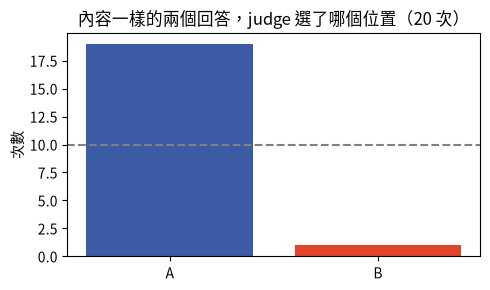

In [8]:
from mini_rag import load_eval_set


class Choice(BaseModel):
    winner: Literal["A", "B"]


PAIR = "你是評審。比較兩個回答，哪一個比較好？"


def pick(q: str, first: str, second: str) -> str:
    return ask(PAIR, f"問題：{q}\n回答 A：{first}\n回答 B：{second}", Choice).winner


pos = pd.DataFrame([
    {"id": e["id"], "原順序": pick(e["question"], e["reference"], "答：" + e["reference"]),
     "對調後": pick(e["question"], "答：" + e["reference"], e["reference"])}
    for e in load_eval_set()[:10]
])
# 修法：正反各問一次，兩次都選同一份「內容」才算贏，否則平手
pos["修正後"] = [{"AB": "原回答", "BA": "加前綴"}.get(a + b, "平手") for a, b in zip(pos["原順序"], pos["對調後"])]
print(pos["修正後"].value_counts().to_dict())

counts = pd.concat([pos["原順序"], pos["對調後"]]).value_counts().reindex(["A", "B"], fill_value=0)
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(counts.index, counts.values, color=["#3b5ba5", "#e0442b"])
ax.axhline(len(pos), ls="--", c="grey")
ax.set_title("內容一樣的兩個回答，judge 選了哪個位置（20 次）")
ax.set_ylabel("次數")
plt.tight_layout()
plt.show()

公正的話 A、B 應該各 10 次（虛線）；實際上幾乎都選同一個位置。正反各問一次之後，大多變成「平手」，這才對。

## Step 7：本課的 judge，以及跟人工的一致率

`judge.py` 把上面學到的都放進去：給參考答案、評分量表寫清楚每個分數的定義、明講長度不加分、附一個「長但錯」的範例、
用 `parse` 拿結構化輸出；再加一條**程式規則**當否決票——參考答案裡的數字，回答都要出現（3B 評審會漏看數字）。

In [9]:
from judge import JUDGE_PROMPT, judge, numbers_in

print(JUDGE_PROMPT[:300], "…\n")
for name, ans in [("簡短正確", short_right), ("冗長錯誤", long_wrong)]:
    v = judge("特休要提前幾天申請？", "要在「嵐葉」提前 3 個工作天申請。", ans)
    print(f"{name}：LLM {v['score']} 分，數字規則 {v['numbers_ok']}，最終 passed={v['passed']}")
print("參考答案的數字：", numbers_in("要在「嵐葉」提前 3 個工作天申請。"))

你是評審，檢查內部助理的回答和參考答案的關鍵事實是否一致。

評分量表：
5 = 關鍵事實全對。簡短、換句話說、多寫了正確的補充，都算 5 分。
4 = 關鍵事實對，但漏了次要細節。
3 = 關鍵事實只對一半。
2 = 主要結論或數字錯。
1 = 完全答非所問，或編造參考答案沒有的內容。

規則：
- 只比對關鍵事實：數字、期限、單位、對象、可不可以。
- 回答的長短和語氣不影響分數。
- 參考答案是「資料中沒有提到」時：回答也說沒有資料 → 5 分；回答給出具體內容 → 1 分。

範例：
問題：補休要多久內用完？ 參考答案：6 個月內。 待評回答：半年內要用掉。
{"reason": "半 …

簡短正確：LLM 3 分，數字規則 True，最終 passed=False
冗長錯誤：LLM 4 分，數字規則 False，最終 passed=False
參考答案的數字： {'3'}


現在把四個評分器一起跑。自寫的評分邏輯可以包成 Opik 指標（繼承 `BaseMetric`、實作 `score`），
然後交給 `opik.evaluate_on_dict_items` 統一呼叫——它不需要伺服器上的資料集。`scoring_threads=1` 是為了不把本機 Ollama 塞爆。

In [10]:
from opik.evaluation.metrics import BaseMetric
from opik.evaluation.metrics.score_result import ScoreResult


class CourseJudge(BaseMetric):
    """本課 judge：LLM 量表 ≥ 4 分且數字規則通過，value = 1。"""

    def score(self, input: str, output: str, reference: str, **ignored) -> ScoreResult:
        v = judge(input, reference, output)
        return ScoreResult(name=self.name, value=float(v["passed"]), reason=v["reason"])


class NaiveJudge(BaseMetric):
    """陽春 judge：沒給參考答案，4 分以上 value = 1。"""

    def score(self, input: str, output: str, **ignored) -> ScoreResult:
        s = ask(NAIVE, f"問題：{input}\n回答：{output}", Score)
        return ScoreResult(name=self.name, value=float(s.score >= 4), reason=s.reason)


# 注意：dict 裡不能有 "id" 這個鍵，Opik 會拿它當資料集項目的 id 而衝突，所以用 sid
items = [{"sid": r.id, "input": r.question, "reference": r.reference, "context": [r.reference],
          "answer": r.answer} for r in samples.itertuples()]
result = opik.evaluate_on_dict_items(
    items=items,
    task=lambda item: {"output": item["answer"]},   # 回答已經寫好，task 只負責交出去
    scoring_metrics=[halluc, NaiveJudge(name="naive", track=False), CourseJudge(name="course", track=False)],
    scoring_threads=1,
)

pred = {}
for tr in result.test_results:
    sid = tr.test_case.dataset_item_content["sid"]
    for s in tr.score_results:
        pred.setdefault(s.name, {})[sid] = None if s.scoring_failed else s.value

print("Hallucination 原始值（1＝有幻覺，None＝計算失敗）：", pred["hallucination_metric"])

samples["pred_字串相似≥0.5"] = samples["levenshtein"].map(lambda v: "pass" if v >= 0.5 else "fail")
samples["pred_Hallucination"] = samples["id"].map(lambda i: "pass" if pred["hallucination_metric"][i] == 0 else "fail")
samples["pred_陽春 judge"] = samples["id"].map(lambda i: "pass" if pred["naive"][i] == 1 else "fail")
samples["pred_本課 judge"] = samples["id"].map(lambda i: "pass" if pred["course"][i] == 1 else "fail")
samples[["id", "human"] + [c for c in samples.columns if c.startswith("pred_")]]

Hallucination 原始值（1＝有幻覺，None＝計算失敗）： {'S01': 1.0, 'S02': 1.0, 'S03': 1.0, 'S04': 1.0, 'S05': 1.0, 'S06': 1.0, 'S07': 1.0, 'S08': 1.0, 'S09': 1.0, 'S10': 1.0}


,id,human,pred_字串相似≥0.5,pred_Hallucination,pred_陽春 judge,pred_本課 judge
0,S01,pass,pass,fail,fail,fail
1,S02,fail,fail,fail,pass,fail
2,S03,pass,pass,fail,fail,pass
3,S04,fail,fail,fail,fail,fail
4,S05,pass,pass,fail,fail,pass
5,S06,fail,fail,fail,pass,fail
6,S07,pass,pass,fail,fail,fail
7,S08,fail,fail,fail,fail,fail
8,S09,pass,pass,fail,fail,fail
9,S10,fail,fail,fail,fail,fail


In [11]:
def agreement(col: str) -> dict:
    h, p = samples["human"], samples[col]
    return {
        "一致率": (h == p).mean(),
        "TPR": ((h == "pass") & (p == "pass")).sum() / (h == "pass").sum(),
        "TNR": ((h == "fail") & (p == "fail")).sum() / (h == "fail").sum(),
    }


cols = [c for c in samples.columns if c.startswith("pred_")]
report = pd.DataFrame({c.removeprefix("pred_"): agreement(c) for c in cols}).T

Path("runs").mkdir(exist_ok=True)  # 存起來，8-05 寫履歷時要引用 judge 的可信度
Path("runs/judge_calibration.json").write_text(
    json.dumps({"n": len(samples), **report.loc["本課 judge"].round(3).to_dict()}, ensure_ascii=False), encoding="utf-8")
report.style.format("{:.0%}")

,一致率,TPR,TNR
字串相似≥0.5,100%,100%,100%
Hallucination,50%,0%,100%
陽春 judge,30%,0%,60%
本課 judge,70%,40%,100%


一致率之外一定要分開看 TPR、TNR：全部判 fail 的評分器，TNR 是 100%、TPR 是 0%，一致率卻還有 50%。

## Step 8：混淆矩陣

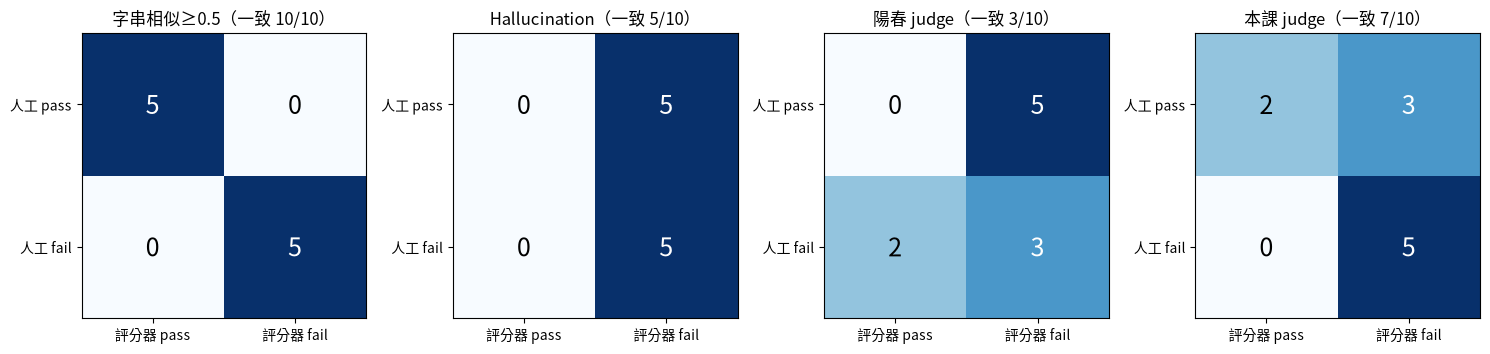

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
labels = ["pass", "fail"]
for ax, col in zip(axes, cols):
    m = np.array([[((samples["human"] == h) & (samples[col] == p)).sum() for p in labels] for h in labels])
    ax.imshow(m, cmap="Blues", vmin=0, vmax=5)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, m[i, j], ha="center", va="center", fontsize=18, color="white" if m[i, j] >= 3 else "black")
    ax.set_xticks([0, 1], [f"評分器 {x}" for x in labels])
    ax.set_yticks([0, 1], [f"人工 {x}" for x in labels])
    ax.set_title(f"{col.removeprefix('pred_')}（一致 {np.trace(m)}/10）")
plt.tight_layout()
plt.show()

左上、右下是對的；右上是好的被攔下，左下是壞的被放行。左下對產品最危險：錯誤答案被放行，分數就虛胖了。

三個值得停下來想的地方：
- **字串相似度在這 10 筆上可能表現很好**——別被騙了。這批樣本裡錯的回答剛好都很長、對的都很短，它量到的其實是長度；
  Step 2 的反例（只改一個數字）它就分不出來。這也提醒你：校準樣本要涵蓋各種錯誤型態，否則量出來的一致率會騙人。
- **Hallucination 的定義跟人工標準不同**：它只管「有沒有超出 context」，回答多一句建議、或換個說法，它都可能判成幻覺；
  而 3B 模型跑英文 prompt，常常整排判 1。現成指標要先在你的資料上量過，才知道能不能用。
- **本課 judge** 的 TNR 通常很高（壞的都抓得到），TPR 偏低（3B 評審挑字眼，好的也被扣分）。

## Step 9：本課 judge 還錯在哪

錯誤分析＝把跟人工不一致的那幾筆印出來，讀理由，而不是「再調調看」。

In [13]:
reasons = {tr.test_case.dataset_item_content["sid"]: {s.name: s.reason for s in tr.score_results}
           for tr in result.test_results}
for r in samples[samples["human"] != samples["pred_本課 judge"]].itertuples():
    print(f"[{r.id}] 人工 {r.human}｜{r.question}")
    print("  回答：", r.answer[:70])
    print("  人工理由：", r.human_reason)
    print("  judge 理由：", reasons[r.id]["course"], "\n")

[S01] 人工 pass｜特休要提前幾天申請？
  回答： 提前 3 個工作天，在嵐葉系統申請。
  人工理由： 數字與系統都對。
  judge 理由： 回答缺少關鍵事實中的「工作天」，但補充了申請系統，關鍵事實只對一半 

[S07] 人工 pass｜推薦朋友進來當工程師，獎金怎麼發？
  回答： 獎金 30,000 元，分兩次發：到職滿 3 個月發 15,000 元，滿 6 個月再發 15,000 元。
  人工理由： 金額與時間點都對，換了說法。
  judge 理由： 回答將獎金分成兩次發，但發放比例和參考答案不一致 

[S09] 人工 pass｜公司帳號密碼有什麼規定？
  回答： 公司帳號密碼長度至少 12 個字元，並且必須同時包含大寫英文、小寫英文與數字，這樣可以提高帳號安全性，降低被暴力破解的風險。
  人工理由： 內容正確，只是比較長。
  judge 理由： 回答了部分内容，但未提及所有关键事实，如未明确指出必须包含数字和大小写字母组合 



常見的剩餘錯誤：需要算術（「一半」＝ 15,000 元）、需要推論（「IT 服務台」不是「資安組」）、或 3B 評審挑字眼給 3 分。
下一步可以換大一點的 judge 模型、加針對性的規則，或接受它並在報告裡寫明一致率。
還有一個本模組刻意接受的限制：受測系統和 judge 都是 `qwen2.5:3b`（自我偏好），寫履歷時要誠實交代。
另外，`judge.py` 裡的範例是另外寫的題目，**不是**從這 10 筆校準樣本挑的，否則就像拿測試集調超參數。

## 試試看

1. 把 `CourseJudge` 的通過門檻從 4 分改成 3 分（要改 `judge.PASS_SCORE`），TPR、TNR 各往哪邊動？
2. 在 `PAIR` 裡加一句「回答的先後順序與好壞無關」，重跑 Step 6。位置偏誤有消失嗎？
3. 把 `metrics.AnswerRelevance(model=JUDGE_LLM, track=False)` 加進 `scoring_metrics`，它跟人工一致嗎？

## 小結

- 評分器由便宜到貴：規則（字串相似度）→ 現成 LLM 指標 → 自寫 judge；越懂你的業務規則，越需要自己寫。
- 自寫 judge 用 `parse`＋Pydantic 拿結構化輸出；給參考答案和量表修長度偏誤，正反各問一次修位置偏誤，漏看的數字用程式規則補。
- 評分器本身要拿人工標註校準：一致率、TPR、TNR、混淆矩陣。下一本 8-02 用本課 judge 對 40 題題庫做回歸評估。